# Bank Good Credit Prediction
## Gradient Boosting Classifier — Model Building & Evaluation

**Project objective:** Classify customers as **Good Credit (0)** or **Bad Credit (1)** using financial and credit-related information.

This notebook builds and evaluates a Gradient Boosting model. It is designed to follow the project's existing dataset structure and to give special attention to the minority **Bad Credit** class.

> **Dataset:** `Data.csv`  
> **Target column:** `Bad_label`  
> **Target mapping:** `0 = Good Credit`, `1 = Bad Credit`

### Notebook workflow
1. Import libraries and load the dataset
2. Prepare features and target
3. Split data using stratification
4. Build a preprocessing and Gradient Boosting pipeline
5. Train, predict and evaluate
6. Review the confusion matrix and feature importance
7. Optional hyperparameter tuning using training data only
8. Summarize findings and limitations

**Important:** Place `Data.csv` in the same folder as this notebook before running it. Do not use customer identifiers as predictive features.

## 1. Business understanding

Credit-risk classification supports a bank's assessment of whether a customer is likely to represent a higher credit risk. In this project:

- **Good Credit (0):** the dataset labels the customer as good credit.
- **Bad Credit (1):** the dataset labels the customer as bad credit.

A false negative occurs when a Bad Credit customer is predicted as Good Credit. This may expose the bank to credit losses. A false positive occurs when a Good Credit customer is predicted as Bad Credit, potentially causing the bank to reject a suitable customer.

The model is a decision-support experiment, not an automatic loan-approval system. Final decisions require independent validation, policy review and human oversight.

## 2. Why Gradient Boosting?

Gradient Boosting is an ensemble method that adds decision trees sequentially. Each new tree focuses on reducing errors made by the current ensemble. The combined model can learn nonlinear patterns and interactions among financial variables.

It is considered here because it:
- can model nonlinear relationships in credit-related data;
- combines multiple small decision trees into an ensemble;
- supports sample weights, which can help address class imbalance during training; and
- provides feature-importance estimates for model interpretation.

Because the dataset is strongly imbalanced, **accuracy must not be used alone**. This notebook reports precision, recall, F1-score, ROC-AUC and average precision (PR-AUC summary), with particular attention to the Bad Credit class.

## 3. Import libraries

In [3]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, PrecisionRecallDisplay,
    RocCurveDisplay
)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

print("Libraries imported successfully.")

Libraries imported successfully.


## 4. Load the dataset

If your CSV file is stored in another folder, update `DATA_PATH` to its full path. On Windows, use a raw string such as `r"C:\Users\YourName\Downloads\Data.csv"`.

In [4]:
DATA_PATH = "Data.csv"  # Update this path if Data.csv is stored elsewhere

df = pd.read_csv(r"C:\Users\91929\OneDrive\Desktop\Bank Good Credit project\Data.csv")

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully.
Dataset shape: (1000, 11)


,customer_no,Bad_label,total_accounts,total_balance,total_past_due,max_high_credit,total_credit_limit,avg_interest_rate,total_enquiries,total_enquiry_amount,avg_enquiry_amount
0,1,0,18,4714857.0,2538209.0,2528846.0,670000.0,17.712,18,4.981150e+06,2.767306e+05
1,2,0,2,30754.0,0.0,1000000.0,1000000.0,NaN,68,6.676682e+09,9.818650e+07
2,3,0,1,17864.0,0.0,121523.0,0.0,NaN,1,3.400000e+06,3.400000e+06
3,4,0,17,1845569.0,0.0,3000000.0,956000.0,23.935,34,5.081000e+07,1.494412e+06
4,5,0,7,7973.0,0.0,12662938.0,0.0,NaN,2,2.000000e+03,1.000000e+03


## 5. Basic dataset inspection

In [5]:
print("Dataset information:")
df.info()

print("\\nMissing values by column:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\\nDuplicate rows:", df.duplicated().sum())

print("\\nTarget distribution:")
display(df["Bad_label"].value_counts(dropna=False).rename(index={
    0: "Good Credit (0)", 1: "Bad Credit (1)"
}).to_frame("Count"))

print("\\nTarget percentage:")
display((df["Bad_label"].value_counts(normalize=True) * 100)
        .rename(index={0: "Good Credit (0)", 1: "Bad Credit (1)"})
        .round(2).to_frame("Percentage"))

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   customer_no           1000 non-null   int64  
 1   Bad_label             1000 non-null   int64  
 2   total_accounts        1000 non-null   int64  
 3   total_balance         1000 non-null   float64
 4   total_past_due        1000 non-null   float64
 5   max_high_credit       1000 non-null   float64
 6   total_credit_limit    1000 non-null   float64
 7   avg_interest_rate     586 non-null    float64
 8   total_enquiries       1000 non-null   int64  
 9   total_enquiry_amount  1000 non-null   float64
 10  avg_enquiry_amount    995 non-null    float64
dtypes: float64(7), int64(4)
memory usage: 86.1 KB
\nMissing values by column:


,Missing Values
customer_no,0
Bad_label,0
total_accounts,0
total_balance,0
total_past_due,0
max_high_credit,0
total_credit_limit,0
avg_interest_rate,414
total_enquiries,0
total_enquiry_amount,0


\nDuplicate rows: 0
\nTarget distribution:


,Count
Bad_label,
Good Credit (0),967
Bad Credit (1),33


\nTarget percentage:


,Percentage
Bad_label,
Good Credit (0),96.7
Bad Credit (1),3.3


## 6. Prepare features and target

The identifier `customer_no` is excluded because it identifies a record rather than representing a customer's credit behaviour. The target `Bad_label` is separated from the predictors.

The code checks that the target exists and contains the expected binary labels. Missing predictor values are handled inside the modelling pipeline, so imputation is learned from the training data only.

In [6]:
TARGET = "Bad_label"
ID_COLUMNS = ["customer_no"]

if TARGET not in df.columns:
    raise ValueError(f"Target column '{TARGET}' was not found. Check the CSV column names.")

# Remove rows where the target is missing; a supervised model cannot learn without labels.
data = df.dropna(subset=[TARGET]).copy()

# Validate the target labels.
observed_labels = set(pd.Series(data[TARGET]).unique())
if not observed_labels.issubset({0, 1}):
    raise ValueError(f"Expected target labels 0 and 1, but found: {observed_labels}")

drop_columns = [col for col in ID_COLUMNS if col in data.columns] + [TARGET]
X = data.drop(columns=drop_columns)
y = data[TARGET].astype(int)

if X.shape[1] == 0:
    raise ValueError("No predictor columns remain after excluding ID and target columns.")

# Identify numeric and categorical predictors.
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

print("Number of records:", len(data))
print("Number of predictors:", X.shape[1])
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("\\nTarget counts:")
print(y.value_counts().sort_index())

Number of records: 1000
Number of predictors: 9
Numeric features: ['total_accounts', 'total_balance', 'total_past_due', 'max_high_credit', 'total_credit_limit', 'avg_interest_rate', 'total_enquiries', 'total_enquiry_amount', 'avg_enquiry_amount']
Categorical features: []
\nTarget counts:
Bad_label
0    967
1     33
Name: count, dtype: int64


## 7. Train-test split

A stratified split preserves approximately the same Good Credit / Bad Credit proportions in both subsets. The test set is held aside for final evaluation and must not be used for fitting preprocessing steps or tuning model parameters.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

print("\\nTraining target distribution:")
display(y_train.value_counts().rename(index={0: "Good Credit", 1: "Bad Credit"}).to_frame("Count"))

print("\\nTesting target distribution:")
display(y_test.value_counts().rename(index={0: "Good Credit", 1: "Bad Credit"}).to_frame("Count"))

Training feature shape: (800, 9)
Testing feature shape: (200, 9)
\nTraining target distribution:


,Count
Bad_label,
Good Credit,774
Bad Credit,26


\nTesting target distribution:


,Count
Bad_label,
Good Credit,193
Bad Credit,7


## 8. Build preprocessing and Gradient Boosting pipeline

Numeric columns are median-imputed. Categorical columns, if present, are imputed with their most frequent value and one-hot encoded. All preprocessing is placed inside the pipeline to prevent information from the test set leaking into training.

Balanced sample weights are calculated from **training labels only**. They increase the contribution of minority-class training observations when fitting the Gradient Boosting model.

In [8]:
transformers = []

if numeric_features:
    numeric_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ])
    transformers.append(("numeric", numeric_pipeline, numeric_features))

if categorical_features:
    categorical_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])
    transformers.append(("categorical", categorical_pipeline, categorical_features))

preprocessor = ColumnTransformer(
    transformers=transformers,
    remainder="drop"
)

gb_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=2,
        min_samples_leaf=4,
        random_state=RANDOM_STATE
    ))
])

train_sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train
)

print("Preprocessing and Gradient Boosting pipeline created.")

Preprocessing and Gradient Boosting pipeline created.


## 9. Train the Gradient Boosting model

In [9]:
gb_pipeline.fit(
    X_train,
    y_train,
    model__sample_weight=train_sample_weights
)

print("Gradient Boosting model trained successfully.")

Gradient Boosting model trained successfully.


## 10. Generate predictions

The predicted class uses the model's default probability threshold. The probability for class `1` is retained for ranking metrics such as ROC-AUC and average precision.

In [10]:
y_pred_gb = gb_pipeline.predict(X_test)
y_prob_gb = gb_pipeline.predict_proba(X_test)[:, 1]

print("Test predictions generated successfully.")
print("First 10 predicted classes:", y_pred_gb[:10])
print("First 10 Bad Credit probabilities:", np.round(y_prob_gb[:10], 4))

Test predictions generated successfully.
First 10 predicted classes: [0 0 0 0 0 0 0 0 0 0]
First 10 Bad Credit probabilities: [0.489  0.1565 0.4741 0.2696 0.0773 0.0777 0.2113 0.0526 0.1395 0.0727]


## 11. Model evaluation

Precision answers: among customers predicted as Bad Credit, how many were actually Bad Credit?

Recall answers: among all actual Bad Credit customers, how many did the model identify?

F1-score balances precision and recall. ROC-AUC measures ranking across thresholds, while average precision summarizes the precision-recall curve and is especially informative for an imbalanced positive class.

The positive class is **Bad Credit (1)**.

In [11]:
metrics = {
    "Accuracy": accuracy_score(y_test, y_pred_gb),
    "Bad Credit Precision": precision_score(y_test, y_pred_gb, pos_label=1, zero_division=0),
    "Bad Credit Recall": recall_score(y_test, y_pred_gb, pos_label=1, zero_division=0),
    "Bad Credit F1-Score": f1_score(y_test, y_pred_gb, pos_label=1, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob_gb),
    "Average Precision (PR-AUC summary)": average_precision_score(y_test, y_prob_gb)
}

evaluation_results = pd.DataFrame(
    {"Metric": list(metrics.keys()), "Score": list(metrics.values())}
)

display(evaluation_results.style.format({"Score": "{:.4f}"}))

print("\\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_gb,
    labels=[0, 1],
    target_names=["Good Credit", "Bad Credit"],
    zero_division=0
))

,Metric,Score
0,Accuracy,0.8650
1,Bad Credit Precision,0.0833
2,Bad Credit Recall,0.2857
3,Bad Credit F1-Score,0.1290
4,ROC-AUC,0.5918
5,Average Precision (PR-AUC summary),0.1033


\nClassification Report:
              precision    recall  f1-score   support

 Good Credit       0.97      0.89      0.93       193
  Bad Credit       0.08      0.29      0.13         7

    accuracy                           0.86       200
   macro avg       0.53      0.59      0.53       200
weighted avg       0.94      0.86      0.90       200



## 12. Confusion matrix

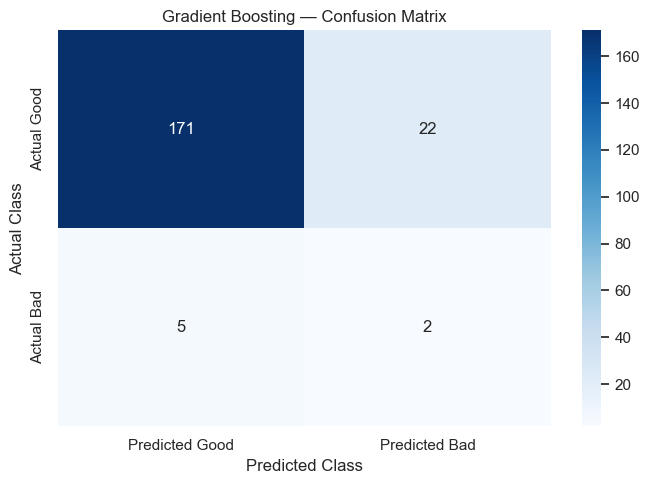

Confusion matrix order: [[True Good, Good predicted Bad],
                         [Bad predicted Good, True Bad]]


In [12]:
cm = confusion_matrix(y_test, y_pred_gb, labels=[0, 1])

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted Good", "Predicted Bad"],
    yticklabels=["Actual Good", "Actual Bad"]
)
plt.title("Gradient Boosting — Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

print("Confusion matrix order: [[True Good, Good predicted Bad],")
print("                         [Bad predicted Good, True Bad]]")

## 13. ROC and Precision-Recall curves

For a highly imbalanced dataset, the Precision-Recall curve is particularly useful because it focuses on performance for the positive (Bad Credit) class. Compare these curves with those of the other project models using the same held-out test set.

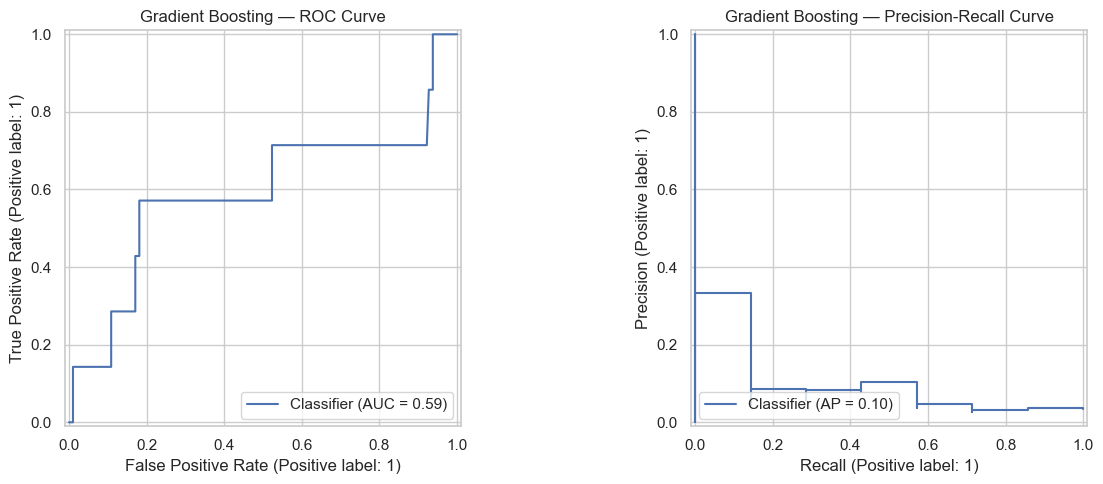

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

RocCurveDisplay.from_predictions(y_test, y_prob_gb, ax=axes[0])
axes[0].set_title("Gradient Boosting — ROC Curve")

PrecisionRecallDisplay.from_predictions(y_test, y_prob_gb, ax=axes[1])
axes[1].set_title("Gradient Boosting — Precision-Recall Curve")

plt.tight_layout()
plt.show()

## 14. Feature importance

Feature importance indicates how much each transformed input feature contributed to the fitted tree ensemble's impurity-based splits. It is a model-specific diagnostic, not evidence that a feature causes credit default. Correlated predictors can share or distort importance.

,Feature,Importance
4,numeric__total_credit_limit,0.241502
8,numeric__avg_enquiry_amount,0.232016
1,numeric__total_balance,0.171651
6,numeric__total_enquiries,0.165550
0,numeric__total_accounts,0.088300
7,numeric__total_enquiry_amount,0.072632
5,numeric__avg_interest_rate,0.017167
3,numeric__max_high_credit,0.011183
2,numeric__total_past_due,0.000000


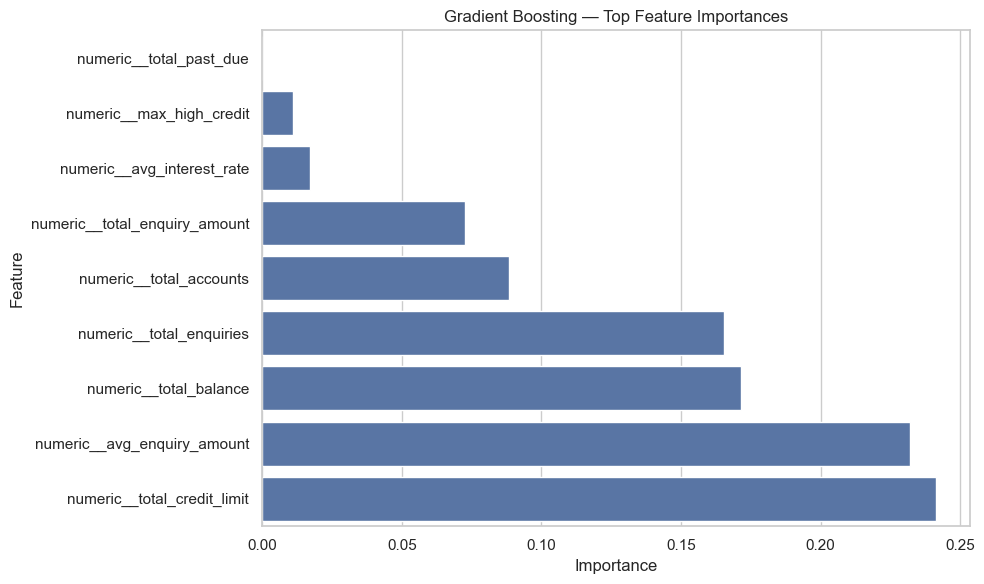

In [14]:
fitted_preprocessor = gb_pipeline.named_steps["preprocessor"]
fitted_model = gb_pipeline.named_steps["model"]

try:
    transformed_feature_names = fitted_preprocessor.get_feature_names_out()
    importance_values = fitted_model.feature_importances_

    feature_importance = pd.DataFrame({
        "Feature": transformed_feature_names,
        "Importance": importance_values
    }).sort_values("Importance", ascending=False)

    display(feature_importance)

    top_features = feature_importance.head(15).sort_values("Importance")
    plt.figure(figsize=(10, 6))
    sns.barplot(data=top_features, x="Importance", y="Feature")
    plt.title("Gradient Boosting — Top Feature Importances")
    plt.xlabel("Importance")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.show()

except Exception as error:
    print("Feature importance could not be displayed:", error)

## 15. Optional: Hyperparameter tuning

Run this section only after the baseline model has been evaluated. GridSearchCV uses stratified cross-validation on the training set and optimizes average precision, which is more informative than accuracy for this imbalanced classification problem.

The test set is not passed to GridSearchCV. With very few Bad Credit examples, cross-validation scores can vary substantially; interpret them cautiously. This search can take several minutes.

In [ ]:
RUN_TUNING = True  # Change to False to skip tuning

if RUN_TUNING:
    param_grid = {
        "model__n_estimators": [75, 100, 150],
        "model__learning_rate": [0.03, 0.05, 0.1],
        "model__max_depth": [1, 2, 3],
        "model__min_samples_leaf": [2, 4, 6]
    }

    min_class_count = int(y_train.value_counts().min())
    n_splits = min(5, min_class_count)

    if n_splits < 2:
        print("Not enough minority-class training examples for stratified CV. Tuning skipped.")
        best_gb_model = gb_pipeline
    else:
        cv_strategy = StratifiedKFold(
            n_splits=n_splits,
            shuffle=True,
            random_state=RANDOM_STATE
        )

        grid_search = GridSearchCV(
            estimator=gb_pipeline,
            param_grid=param_grid,
            scoring="average_precision",
            cv=cv_strategy,
            n_jobs=-1,
            verbose=1,
            refit=True
        )

        grid_search.fit(
            X_train,
            y_train,
            model__sample_weight=train_sample_weights
        )

        best_gb_model = grid_search.best_estimator_
        print("Best parameters:", grid_search.best_params_)
        print("Best cross-validation average precision:", round(grid_search.best_score_, 4))
else:
    best_gb_model = gb_pipeline
    print("Tuning skipped. Baseline Gradient Boosting model retained.")

Fitting 5 folds for each of 81 candidates, totalling 405 fits


## 16. Evaluate the selected model on the held-out test set

If tuning was run, the selected estimator is refitted by GridSearchCV using training data only. The test set is evaluated here after model selection. Do not repeatedly adjust the model based on test results; use a separate validation set or nested cross-validation for further development.

In [ ]:
y_pred_final = best_gb_model.predict(X_test)
y_prob_final = best_gb_model.predict_proba(X_test)[:, 1]

final_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred_final),
    "Bad Credit Precision": precision_score(y_test, y_pred_final, pos_label=1, zero_division=0),
    "Bad Credit Recall": recall_score(y_test, y_pred_final, pos_label=1, zero_division=0),
    "Bad Credit F1-Score": f1_score(y_test, y_pred_final, pos_label=1, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob_final),
    "Average Precision": average_precision_score(y_test, y_prob_final)
}

display(pd.DataFrame(
    {"Metric": list(final_metrics.keys()), "Score": list(final_metrics.values())}
).style.format({"Score": "{:.4f}"}))

print(classification_report(
    y_test,
    y_pred_final,
    labels=[0, 1],
    target_names=["Good Credit", "Bad Credit"],
    zero_division=0
))

## 17. Results interpretation — report-ready template

Complete this section after running the notebook. Insert the actual values from the evaluation table; do not invent or estimate performance scores.

**Suggested interpretation:**

The Gradient Boosting Classifier was developed to classify customers into Good Credit and Bad Credit categories using the available financial attributes. Balanced sample weights were used during training to give greater importance to the minority Bad Credit class. The model was assessed using accuracy, precision, recall, F1-score, ROC-AUC, average precision and a confusion matrix.

For credit-risk analysis, Bad Credit recall measures the proportion of actual Bad Credit customers identified by the model, while Bad Credit precision measures the reliability of the model's Bad Credit predictions. These metrics should be considered together because increasing recall can also increase false-positive predictions.

Feature importance was reviewed to understand which input variables the fitted model relied on most. These importance scores describe model behaviour and should not be interpreted as causal relationships.

**Conclusion:** Gradient Boosting is a useful candidate for bank credit-risk classification. Its suitability must be judged against the other project models and the bank's relative costs of missed risky customers and incorrectly flagged good customers. Independent validation, threshold assessment, fairness checks and human review are required before any operational use.

## 18. Save the trained model (optional)

The saved artifact includes the full preprocessing-and-model pipeline and metadata. Save it only if you have permission to store and share the dataset-derived model. Load it later with `joblib.load()` in a compatible Python / scikit-learn environment.

> Pickle/joblib files can execute code when loaded. Only load model files from trusted sources. Scikit-learn does not guarantee compatibility across versions.

In [ ]:
import joblib
from datetime import datetime

model_artifact = {
    "model": best_gb_model,
    "model_name": "Gradient Boosting Classifier",
    "target_column": TARGET,
    "target_mapping": {0: "Good Credit", 1: "Bad Credit"},
    "feature_columns": X.columns.tolist(),
    "excluded_columns": [col for col in ID_COLUMNS if col in df.columns] + [TARGET],
    "training_rows": int(len(X_train)),
    "random_state": RANDOM_STATE,
    "evaluation_metrics": final_metrics,
    "created_at": datetime.now().isoformat(timespec="seconds")
}

OUTPUT_MODEL_PATH = "Bank_Good_Credit_Gradient_Boosting.joblib"
joblib.dump(model_artifact, OUTPUT_MODEL_PATH)

print(f"Model artifact saved as: {OUTPUT_MODEL_PATH}")

## 19. How to load the saved model

Run this in a later notebook or application, using a compatible environment and a trusted model file.

In [ ]:
import joblib

loaded_artifact = joblib.load("Bank_Good_Credit_Gradient_Boosting.joblib")
loaded_model = loaded_artifact["model"]

print("Model loaded successfully.")
print("Model:", loaded_artifact["model_name"])
print("Expected predictors:", loaded_artifact["feature_columns"])

## 20. Project limitations and responsible use

- The dataset contains substantially fewer Bad Credit records than Good Credit records. Results may be unstable because the minority class is small.
- A single train-test split can produce volatile estimates. Consider repeated stratified validation or nested cross-validation.
- The default classification threshold may not reflect the bank's business costs. Thresholds should be selected using validation data and documented risk criteria.
- Feature importance is not causation and may be affected by correlated variables.
- Negative or unusual financial values should be checked with the data owner rather than removed automatically.
- Confirm that all features are available at the time a real prediction would be made; remove any information that leaks the outcome.
- Assess fairness, privacy, explainability, regulatory requirements and human oversight before operational use.

### Final project takeaway

This notebook provides a reproducible Gradient Boosting workflow for the Bank Good Credit Prediction project. The model should be compared with the project's other classifiers using consistent validation procedures, with emphasis on identifying Bad Credit customers without creating an unacceptable number of false alarms.